# 04: Robustness tests for notebook 03's bound

Notebook 03 concluded:

> **(A)** At rest, the beam-measured screening can't extend beyond ~0.13–0.16 Å, or loaded Pd/Ti would have shown neutrons.
> **(B)** Wherever beam-consistent screening approaches watt-level rates, it exceeds the 1990 neutron limit by ~15 orders of magnitude.

Both rested on one screening shape (exponential), one lattice model (harmonic), one attempt frequency and one null limit. This notebook varies each and asks whether (A) and (B) survive.

| Test | Variants |
|---|---|
| Screening shape | exponential (baseline), Gaussian (short-tailed), step (sharp edge), Yukawa-type (long −q/R tail) |
| Lattice confinement | harmonic (baseline) vs **capped** at the site-to-site diffusion barrier (0.1–0.4 eV) |
| Lattice parameters | pair spacing 2.75 / 2.0 / 1.5 Å; Thomas–Fermi length 0.3–1.0 Å; phonon 20–60 meV |
| Kinetics | tunneling attempt frequency ×10⁻³ to ×10³ |
| Null limit | 2×10⁻²⁶ (PRL 1990) vs 3.6×10⁻²³ (Badurek et al. 1989, weaker) |

Every variant is matched to the **same beam measurement**: the screening equals $U_{\rm meas}$ at the beam's turning point (0.004 Å).

In [1]:
import numpy as np, matplotlib.pyplot as plt, time
from cfsolve import *
plt.rcParams.update({"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,
                     "grid.alpha":.25,"font.size":10,"axes.titlesize":11})
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#0b0b0b", "#52514e"
LOG_WATT, LOG_LIMIT, LOG_LIMIT_WEAK = np.log10(5.6e-11), np.log10(2e-26), np.log10(3.6e-23)
NU0 = 37e-3/4.135667e-15
ELLS = np.logspace(np.log10(0.01), np.log10(0.4), 32)

def analyze(lat_kw=None, shape="exponential", U=300, nu_factor=1.0, ells=ELLS):
    # Sweep the screening range along the beam-consistent curve for one model variant.
    lat_kw = lat_kw or {}
    Vb = V_lattice(**lat_kw); d0 = lat_kw.get("d0_A", 2.75)/BOHR_A
    Rmax = d0 + 7.0; Rmin = 0.4*d0
    E_lat = solve(Vb, Rmax, Rmin_well=Rmin)["E"]
    nu = NU0*lat_kw.get("phonon_meV", 37.0)/37.0*nu_factor
    eff, fuse, leak, rb = [], [], [], []
    for ell in ells:
        ex = extra_screening(beam_matched_dU(U, ell, shape), ell, shape); V = lambda R: Vb(R) + ex(R)
        try:
            lr = solve(V, Rmax, Rmin_well=Rmin)["log10_rate"]
            eff.append(lr); fuse.append(np.nan); leak.append(np.nan); rb.append(np.nan)
        except Collapse:
            B = solve(V, Rmax, Rmin_well=1e-4)
            r = np.logspace(-4, np.log10(Rmax), 200000); v = V(r)
            imin = np.argmin(np.where(r < Rmin, v, np.inf))
            sel = (r > r[imin]) & (r < d0) & (v > E_lat)
            G = 2*np.trapezoid(np.sqrt(2*MU_DD*np.clip(v[sel] - E_lat, 0, None)), r[sel])
            lk = np.log10(nu) - G/np.log(10)
            eff.append(min(lk, B["log10_rate"])); fuse.append(B["log10_rate"]); leak.append(lk)
            rb.append(float(np.trapezoid(B["r"]*B["u"]**2, B["r"]))*BOHR_A)
    eff = np.array(eff); fuse = np.array(fuse); rb = np.array(rb)
    kb = np.where(np.isfinite(fuse))[0]
    first = lambda thr: (ells[np.where(eff > thr)[0][0]] if np.any(eff > thr) else np.nan)
    i_max = int(np.argmax(eff))
    return dict(eff=eff, fuse=fuse, ell_bound=ells[kb[0]] if len(kb) else np.nan,
                r_bound=rb[kb[0]] if len(kb) else np.nan,
                ell_null=first(LOG_LIMIT), ell_null_weak=first(LOG_LIMIT_WEAK), ell_watt=first(LOG_WATT),
                max_eff=eff.max(), ell_at_max=ells[i_max],
                # margin: how far above the null limit is the rate wherever it is within 2 decades of watt level
                min_rate_near_watt=(eff[eff > LOG_WATT - 2].min() if np.any(eff > LOG_WATT - 2) else np.nan))

def show(name, r):
    f = lambda x: "  —  " if not np.isfinite(x) else f"{x:5.3f}"
    print(f"{name:42s} bound@{f(r['ell_bound'])}  null@{f(r['ell_null'])}  weak-null@{f(r['ell_null_weak'])}  "
          f"max 10^{r['max_eff']:6.1f}  watt@{f(r['ell_watt'])}")
t0 = time.time(); base = analyze(); show("baseline (exp, harmonic, 300 eV)", base); print(f"[{time.time()-t0:.0f}s per variant]")

baseline (exp, harmonic, 300 eV)           bound@0.108  null@0.154  weak-null@0.174  max 10^ -17.9  watt@  —  
[14s per variant]


## 1. Screening shape

In [2]:
shape_res = {}
for U in [165, 300, 575]:
    print(f"U_meas = {U} eV")
    for sh in ["exponential", "gaussian", "step", "yukawa"]:
        shape_res[(sh, U)] = r = analyze(shape=sh, U=U); show(f"   {sh}", r)

U_meas = 165 eV


   exponential                             bound@0.174  null@  —    weak-null@  —    max 10^ -27.2  watt@  —  


   gaussian                                bound@0.174  null@  —    weak-null@  —    max 10^ -28.2  watt@  —  


   step                                    bound@0.122  null@  —    weak-null@  —    max 10^ -37.7  watt@  —  


   yukawa                                  bound@0.047  null@  —    weak-null@  —    max 10^ -31.3  watt@  —  
U_meas = 300 eV


...

   yukawa                                  bound@0.026  null@0.042  weak-null@0.047  max 10^ -19.6  watt@  —  
U_meas = 575 eV


   exponential                             bound@0.060  null@0.137  weak-null@0.154  max 10^ -11.3  watt@  —  


   gaussian                                bound@0.060  null@0.315  weak-null@0.315  max 10^ -19.1  watt@  —  


   step                                    bound@0.042  null@  —    weak-null@  —    max 10^ -33.6  watt@  —  


   yukawa                                  bound@0.013  null@0.018  weak-null@0.020  max 10^  -9.6  watt@0.029


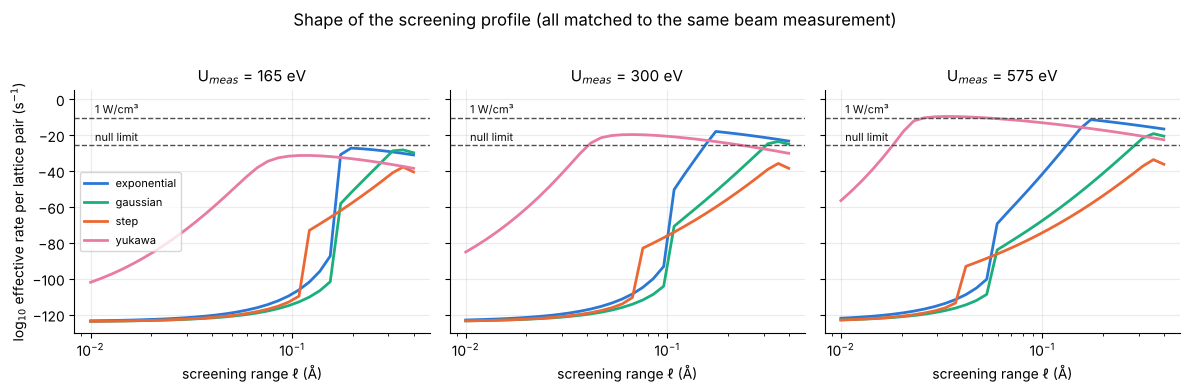

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
cols = {"exponential": BLUE, "gaussian": AQUA, "step": ORANGE, "yukawa": MAGENTA}
for ax, U in zip(axes, [165, 300, 575]):
    for sh, col in cols.items():
        ax.plot(ELLS, shape_res[(sh, U)]["eff"], color=col, lw=2, label=sh)
    for y, lab in [(LOG_WATT, "1 W/cm³"), (LOG_LIMIT, "null limit")]:
        ax.axhline(y, color=MUTED, ls="--", lw=1); ax.text(0.0105, y+2.5, lab, fontsize=8, color=INK)
    ax.set_xscale("log"); ax.set_ylim(-130, 5); ax.set_title(f"U$_{{meas}}$ = {U} eV"); ax.set_xlabel("screening range ℓ (Å)")
axes[0].set_ylabel("log$_{10}$ effective rate per lattice pair (s$^{-1}$)"); axes[0].legend(fontsize=8, loc="center left")
fig.suptitle("Shape of the screening profile (all matched to the same beam measurement)", y=1.02)
plt.tight_layout(); plt.savefig("../figures/04_shapes.png", dpi=130, bbox_inches="tight"); plt.show()

## 2. Lattice model

In [4]:
lat_variants = [
  ("harmonic (baseline)",            {}),
  ("capped at 0.40 eV barrier",      dict(confinement="capped", barrier_eV=0.40)),
  ("capped at 0.23 eV barrier",      dict(confinement="capped", barrier_eV=0.23)),
  ("capped at 0.10 eV barrier",      dict(confinement="capped", barrier_eV=0.10)),
  ("spacing 2.0 A",                  dict(d0_A=2.0)),
  ("spacing 1.5 A (vacancy-like)",   dict(d0_A=1.5)),
  ("Thomas-Fermi 0.3 A",             dict(lam_TF_A=0.3)),
  ("Thomas-Fermi 1.0 A",             dict(lam_TF_A=1.0)),
  ("phonon 20 meV",                  dict(phonon_meV=20.0)),
  ("phonon 60 meV",                  dict(phonon_meV=60.0)),
  ("capped 0.10 eV + spacing 1.5 A", dict(confinement="capped", barrier_eV=0.10, d0_A=1.5)),
]
lat_res = {}
for U in [300, 575]:
    print(f"U_meas = {U} eV (exponential profile)")
    for name, kw in lat_variants:
        lat_res[(name, U)] = r = analyze(lat_kw=kw, U=U); show(f"   {name}", r)

U_meas = 300 eV (exponential profile)


   harmonic (baseline)                     bound@0.108  null@0.154  weak-null@0.174  max 10^ -17.9  watt@  —  


   capped at 0.40 eV barrier               bound@0.108  null@0.154  weak-null@0.174  max 10^ -17.9  watt@  —  


   capped at 0.23 eV barrier               bound@0.108  null@0.154  weak-null@0.174  max 10^ -17.9  watt@  —  


   capped at 0.10 eV barrier               bound@0.108  null@0.154  weak-null@0.154  max 10^ -17.9  watt@  —  


...

   Thomas-Fermi 0.3 A                      bound@0.060  null@0.085  weak-null@0.085  max 10^  -9.4  watt@0.122


   Thomas-Fermi 1.0 A                      bound@0.067  null@0.196  weak-null@0.221  max 10^ -13.5  watt@  —  


   phonon 20 meV                           bound@0.060  null@0.137  weak-null@0.137  max 10^ -11.3  watt@  —  


   phonon 60 meV                           bound@0.067  null@0.154  weak-null@0.174  max 10^ -12.0  watt@  —  


   capped 0.10 eV + spacing 1.5 A          bound@0.060  null@0.108  weak-null@0.122  max 10^ -10.1  watt@0.137


## 3. Kinetics: attempt frequency

In [5]:
kin_res = {}
for U in [300, 575]:
    print(f"U_meas = {U} eV")
    for fac in [1e-3, 1.0, 1e3]:
        kin_res[(fac, U)] = r = analyze(U=U, nu_factor=fac); show(f"   attempt frequency x{fac:g}", r)

U_meas = 300 eV


   attempt frequency x0.001                bound@0.108  null@0.174  weak-null@0.174  max 10^ -18.5  watt@  —  


   attempt frequency x1                    bound@0.108  null@0.154  weak-null@0.174  max 10^ -17.9  watt@  —  


   attempt frequency x1000                 bound@0.108  null@0.154  weak-null@0.154  max 10^ -17.9  watt@  —  
U_meas = 575 eV


   attempt frequency x0.001                bound@0.060  null@0.154  weak-null@0.154  max 10^ -12.0  watt@  —  


   attempt frequency x1                    bound@0.060  null@0.137  weak-null@0.154  max 10^ -11.3  watt@  —  


   attempt frequency x1000                 bound@0.060  null@0.137  weak-null@0.137  max 10^ -11.3  watt@  —  


## 4. Do conclusions (A) and (B) survive?

* **(A) range bound:** across all variants, collect the range at which the effective rate first exceeds the null limit (2×10⁻²⁶; and the weaker 3.6×10⁻²³).
* **(B) no watts without neutrons:** the two thresholds are 15.5 decades apart, so the test is whether any variant reaches watt level at a range where it is *still below* the null limit. That would need a single jump from below 10⁻²⁶ to near 10⁻¹⁰.

In [6]:
allres = {**{(f"shape:{k[0]}", k[1]): v for k, v in shape_res.items()},
          **{(f"lattice:{k[0]}", k[1]): v for k, v in lat_res.items()},
          **{(f"attempt x{k[0]:g}", k[1]): v for k, v in kin_res.items()}}
rows = []
for (name, U), r in allres.items():
    jumps = np.diff(r["eff"]); j = np.argmax(jumps)
    # watts-before-neutrons would show as a single step from below the null limit to near watt level
    leap = (r["eff"][j] < LOG_LIMIT) and (r["eff"][j+1] > LOG_WATT - 2)
    rows.append((name, U, r["ell_null"], r["ell_null_weak"], r["max_eff"], r["ell_watt"], leap))
print(f"{'variant':44s} {'U':>4s}  {'null@':>6s} {'weak@':>6s} {'max':>7s} {'watt@':>6s}  watts-before-neutrons?")
for name, U, a, b, m, w, leap in rows:
    f = lambda x: "   —  " if not np.isfinite(x) else f"{x:6.3f}"
    print(f"{name:44s} {U:4d}  {f(a)} {f(b)} {m:7.1f} {f(w)}  {'YES' if leap else 'no'}")
nulls = np.array([a for _, _, a, _, _, _, _ in rows]); nulls = nulls[np.isfinite(nulls)]
weak  = np.array([b for _, _, _, b, _, _, _ in rows]); weak = weak[np.isfinite(weak)]
print(f"\nrange bound (A), strict limit : {nulls.min():.3f} – {nulls.max():.3f} A over {len(nulls)} constrained variants "
      f"(median {np.median(nulls):.3f})")
print(f"range bound (A), weak limit   : {weak.min():.3f} – {weak.max():.3f} A")
reach = [(n, U, m) for n, U, _, _, m, _, _ in rows if m > LOG_WATT]
print(f"variants that reach 1 W/cm^3 anywhere on the band: {len(reach)}")
for n, U, m in reach: print(f"   {n} @ {U} eV: max 10^{m:.1f}")
print(f"variants with a watts-before-neutrons jump: {sum(r[-1] for r in rows)}")

variant                                         U   null@  weak@     max  watt@  watts-before-neutrons?
shape:exponential                             165     —      —     -27.2    —    no
shape:gaussian                                165     —      —     -28.2    —    no
shape:step                                    165     —      —     -37.7    —    no
shape:yukawa                                  165     —      —     -31.3    —    no
shape:exponential                             300   0.154  0.174   -17.9    —    no
shape:gaussian                                300   0.315    —     -23.5    —    no
shape:step                                    300     —      —     -35.8    —    no
shape:yukawa                                  300   0.042  0.047   -19.6    —    no
shape:exponential                             575   0.137  0.154   -11.3    —    no
shape:gaussian                                575   0.315  0.315   -19.1    —    no
shape:step                                    575     — 

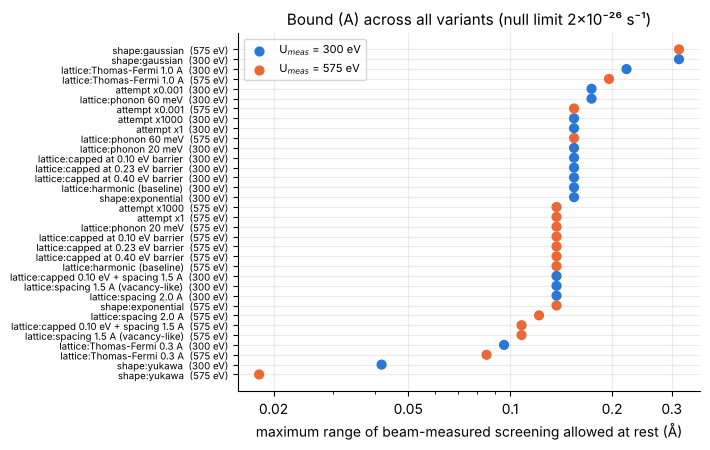

In [7]:
fig, ax = plt.subplots(figsize=(7.2, 4.6))
items = sorted([(n, U, a) for n, U, a, _, _, _, _ in rows if np.isfinite(a)], key=lambda t: t[2])
ys = np.arange(len(items))
ax.scatter([t[2] for t in items], ys, c=[ORANGE if t[1] == 575 else (BLUE if t[1] == 300 else AQUA) for t in items], s=40, zorder=3)
ax.set_yticks(ys); ax.set_yticklabels([f"{t[0]}  ({t[1]} eV)" for t in items], fontsize=7)
from matplotlib.ticker import FixedLocator, FuncFormatter, NullFormatter
ax.set_xscale("log"); ax.xaxis.set_major_locator(FixedLocator([0.02, 0.05, 0.1, 0.2, 0.3]))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}")); ax.xaxis.set_minor_formatter(NullFormatter())
for col, lab in [(BLUE, "U$_{meas}$ = 300 eV"), (ORANGE, "U$_{meas}$ = 575 eV")]:
    ax.scatter([], [], c=col, s=40, label=lab)
ax.legend(fontsize=8, loc="upper left")
ax.set_xlabel("maximum range of beam-measured screening allowed at rest (Å)")
ax.set_title("Bound (A) across all variants (null limit 2×10⁻²⁶ s⁻¹)")
plt.tight_layout(); plt.savefig("../figures/04_range_bound.png", dpi=130); plt.show()

## 5. Verdict (written after the run; numbers from the tables above)

**(B) "No watts without neutrons" survives all 40 variants.** Four variants reach 1 W/cm³ somewhere on the band, all at the strong end ($U_{\rm meas}$ = 575 eV): the long-tailed Yukawa profile, the 1.5 Å vacancy-like spacing (with or without a capped lattice) and a 0.3 Å Thomas–Fermi length. In **every** one of them the rate crosses the neutron limit at a shorter range than it reaches watts (e.g. Yukawa: null limit at 0.018 Å, watts at 0.029 Å). No variant jumps from below the null limit straight to watts. **For screening plus confinement, watts imply neutrons. This is the most robust result of the series.**

**(A) The range bound survives, but as a range of values, not a single number.**
* Where the null limit constrains the screening at all, the maximum range allowed at rest is **0.018–0.315 Å** (median 0.137 Å) across 34 variants. The upper end is ~9× smaller than the 2.75 Å deuteron spacing in PdD.
* **Profile shape dominates.** The long-tailed Yukawa form is constrained tightly (0.02–0.04 Å, only ~5–10× the beam turning point), the Gaussian loosely (0.3 Å).
* **Some cases are unconstrained.** All 165 eV variants and every step-profile variant stay below the null limit everywhere. In those cases the static data can't bound the range, but those cases also never come within 20 orders of watt level.
* The weaker 1989 limit (3.6×10⁻²³) loosens the bound only slightly, because the rate rises steeply.

**What barely matters (a correction to notebook 03's caveat).** Capping the lattice restoring force at the diffusion barrier gives *identical* results to the harmonic model. The phonon energy and the tunneling attempt frequency (×10⁻³ to ×10³) shift the bound by ≲20%. The physics is decided at sub-ångström separations, where the lattice's long-range stiffness is irrelevant. **What does matter:** the profile shape, and the Thomas–Fermi screening length (0.3 Å tightens the bound to ~0.09 Å; 1.0 Å loosens it to ~0.2 Å).

**What none of this tests:** mechanisms with no neutron branch (heat only), many-body/coherent effects, or defect geometries unlike a single pair in a radial potential. Those are outside a single-pair potential model by construction, and they are where the remaining "something missing" would have to live.

**Status of inputs:** same as notebook 03, plus the D-in-Pd diffusion barrier (~0.2–0.23 eV, standard literature value, varied 0.1–0.4 eV) and the Badurek et al. 1989 limit (3.6×10⁻²³ s⁻¹, abstract-level).